# 01 – Data Exploration: AI4Mars (Curiosity Navcam)

Exploring the AI4Mars dataset before building the segmentation model:
folder structure, file pairing, image sizes, label values, class balance and camera types.

**Data:** AI4Mars merged v0.6 (NASA JPL, CC BY 4.0), `msl/ncam` subset.

**Goal:** understand the data well enough to make the decisions listed at the end.

## Setup

In [7]:
from pathlib import Path
import numpy as np 
from PIL import Image
import matplotlib.pyplot as plt 

DATA_DIR = Path(r"C:\data-mars\msl\ncam")
IMG_DIR = DATA_DIR / "images" / "edr"
ROVER_DIR = DATA_DIR / "images" / "mxy"
RANGE_DIR = DATA_DIR / "images" / "rng-30m"
TRAIN_LBL_DIR = DATA_DIR / "labels" / "train"
TEST_LBL_DIR = DATA_DIR / "labels" / "test" / "masked-gold-min3-100agree"

for d in [IMG_DIR, ROVER_DIR, RANGE_DIR, TRAIN_LBL_DIR, TEST_LBL_DIR]:
    print(d.name, d.exists())

edr True
mxy True
rng-30m True
train True
masked-gold-min3-100agree True


### 1. **Folder structure** 


In [ ]:
# exploring the names 

# searches the edr folder for every file ending in .JPG
# produces them one by one as a generator, and sorted(...) collects them into a sorted list of Path objects
all_imgs = sorted(IMG_DIR.glob("*.JPG"))  # gives a list of all image file paths 
#using "*.png" for labels and masks 
print(len(all_imgs))

# tuples: a folder, and the pattern to search it with
folders = [
    (IMG_DIR, "*.JPG"),
    (ROVER_DIR, "*.png"),
    (RANGE_DIR, "*.png"),
    (TRAIN_LBL_DIR, "*.png"),
    (TEST_LBL_DIR, "*.png"),
]

for d, pattern in folders:
    files = sorted(d.glob(pattern))
    print(d.name, len(files))
    for p in files[:3]: # p is one Path at a time, and p.name is its filename
        print("   ", p.name)

18127
edr 18127
    NLA_397586928EDR_F0010008AUT_04096M1.JPG
    NLA_397586934EDR_F0010008AUT_04096M1.JPG
    NLA_397681339EDR_F0020000AUT_04096M1.JPG
mxy 18097
    NLA_397586928MXY_F0010008AUT_04096M1.png
    NLA_397586934MXY_F0010008AUT_04096M1.png
    NLA_397681339MXY_F0020000AUT_04096M1.png
rng-30m 18096
    NLA_397586928RNG_F0010008AUT_04096M1.png
    NLA_397586934RNG_F0010008AUT_04096M1.png
    NLA_397681339RNG_F0020000AUT_04096M1.png
train 16064
    NLA_397586934EDR_F0010008AUT_04096M1.png
    NLA_397681339EDR_F0020000AUT_04096M1.png
    NLA_397681372EDR_F0020000AUT_04096M1.png
masked-gold-min3-100agree 322
    NLA_409036068EDR_F0051606NCAM00348M1_merged.png
    NLA_409036116EDR_F0051606NCAM00348M1_merged.png
    NLA_409036860EDR_F0051662NCAM00346M1_merged.png


The naming pattern, the key to matching:

Folder	Example name
- image (edr)	NLA_397586934EDR_F0010008AUT_04096M1.JPG
- train label	NLA_397586934EDR_F0010008AUT_04096M1.png
- test label	NLA_409036068EDR_F0051606NCAM00348M1_merged.png
- rover mask	NLA_397586934MXY_F0010008AUT_04096M1.png
- range mask	NLA_397586934RNG_F0010008AUT_04096M1.png

So:
- Train label ↔ image: identical stem, only the extension differs.
- Test label ↔ image: same, but remove _merged first.
- Masks ↔ image: replace MXY or RNG with EDR.

(NLA = Navcam left camera A, and the long number is the spacecraft clock time when the photo was taken.)

In [4]:
img_stems = set()
for img in all_imgs:
    img_stems.add(img.stem)

train_stems = set()
for lbl in sorted(TRAIN_LBL_DIR.glob("*.png")):
    train_stems.add(lbl.stem)

test_stems = set() 
for lbl in sorted(TEST_LBL_DIR.glob("*.png")):
    test_stems.add(lbl.stem.replace("_merged", ""))

train_lbl_with_img = train_stems & img_stems
test_lbl_with_img = test_stems & img_stems
train_test_overlap = train_stems & test_stems #must be empty!
img_with_no_lbl = img_stems - train_stems - test_stems

print(len(train_lbl_with_img), "train labels with an image")
print(len(test_lbl_with_img), "test labels with an image")
print(len(train_test_overlap), "train_test overlap")
print(len(img_with_no_lbl), "images iwth no label")


16064 train labels with an image
322 test labels with an image
0 train_test overlap
1741 images iwth no label


### 2. **Sizes** 

- All images and labels are 1024×1024, greyscale (L).
- Decision: model input = 1 channel. Resize to 512×512 for training (four times fewer pixels, so faster and less memory; papers on this dataset do the same). Use nearest-neighbour interpolation for labels.

In [8]:
import random 
from collections import Counter # works like a dictionary that counts things

random.seed(0) # so that the same random picks every run, reproducible 

all_imgs = sorted(IMG_DIR.glob("*.JPG")) 
train_lbls = sorted(TRAIN_LBL_DIR.glob("*.png"))
sample = random.sample(all_imgs, 50)
sample_train = random.sample(train_lbls, 50)

sizes = Counter()
modes = Counter()

for p in sample:
    with Image.open(p) as img: 
        sizes[img.size] += 1
        modes[img.mode] += 1

print(sizes)
print(modes)

sizes_lbl = Counter()
modes_lbl = Counter() 

for s in sample_train:
    with Image.open(s) as lbl:
        sizes_lbl[lbl.size] += 1
        modes_lbl[lbl.mode] += 1

print(sizes_lbl)
print(modes_lbl)

Counter({(1024, 1024): 50})
Counter({'L': 50})
Counter({(1024, 1024): 50})
Counter({'L': 50})


### 3. **Label values** 

In [10]:
# looking at actual pixel values 

train_lbls = sorted(TRAIN_LBL_DIR.glob("*.png"))
sample_train = random.sample(train_lbls, 50)
test_lbls = sorted(TEST_LBL_DIR.glob("*.png"))
sample_test = random.sample(test_lbls, 50)

for p in sample_train[:5]:
    with Image.open(p) as lbl:
        arr = np.array(lbl) # a 1024x1024 grid of numbers 
        print(p.name, np.unique(arr, return_counts=True))

for p in sample_test[:5]:
    with Image.open(p) as lbl:
        arr = np.array(lbl) 
        print(p.name, np.unique(arr, return_counts=True))

all_values = set()
empty = 0

for p in sample_train:
    with Image.open(p) as lbl:
        arr = np.array(lbl) 
        all_values.update(np.unique(arr).tolist())
        if (arr == 255).all():
            empty += 1

print("values seen:", sorted(all_values))
print("empty labels:", empty, "of", len(sample_train))

# reset for test loop 
all_values = set()
empty = 0

for p in sample_test:
    with Image.open(p) as lbl:
        arr = np.array(lbl) 
        all_values.update(np.unique(arr).tolist())
        if (arr == 255).all():
            empty += 1

print("values seen:", sorted(all_values))
print("empty labels:", empty, "of", len(sample_test))


NLB_544785712EDR_F0620408NCAM00385M1.png (array([  1,   2,   3, 255], dtype=uint8), array([142970, 679548,  13961, 212097]))
NLB_539893414EDR_F0610000NCAM00653M1.png (array([  0,   1, 255], dtype=uint8), array([  6683, 610521, 431372]))
NLB_444012884EDR_F0251468NCAM00470M1.png (array([  0, 255], dtype=uint8), array([388191, 660385]))
NLB_624674284EDR_F0770292NCAM00293M1.png (array([  0, 255], dtype=uint8), array([234251, 814325]))
NLB_555961628EDR_F0650436NCAM00312M1.png (array([  1,   2, 255], dtype=uint8), array([457880, 256054, 334642]))
NLB_556764110EDR_F0651642NCAM07753M1_merged.png (array([  1,   2, 255], dtype=uint8), array([  2432,  75746, 970398]))
NLB_520359057EDR_F0550940NCAM00654M1_merged.png (array([  1,   2, 255], dtype=uint8), array([119310,  28153, 901113]))
NLB_577095146EDR_F0691858NCAM00376M1_merged.png (array([  2, 255], dtype=uint8), array([527469, 521107]))
NLB_500656502EDR_F0503076NCAM00353M1_merged.png (array([  0,   1, 255], dtype=uint8), array([ 29229, 103471, 

1. Only the expected values appear: 0, 1, 2, 3, 255. 

2. Each image only contains a few classes. Most labels have just 1–3 of the 4 classes (e.g. only soil, or bedrock + sand). The model will learn from many images that each show a small slice of the terrain types.

3. A lot of pixels are unlabelled (255):

- Train: roughly 20–80% unlabelled. For example, 212,097 of 1,048,576 pixels is about 20%.
- Test (min3): much sparser, often 85–98% unlabelled. One test label has only about 26,500 labelled pixels out of a million (~2.5%).

4. “Big rock” (3) is rare.

    It appears in only one of the 10 printed labels, at about 14,000 pixels (~1.3% of that image).
    It doesn’t appear at all in the test sample.

5. Some labels are completely empty:

- Train: 1 of 50 (~2%), so roughly 300 of the 16,064.
- Test: 5 of 50 (10%).

### 4. **Visualise** 

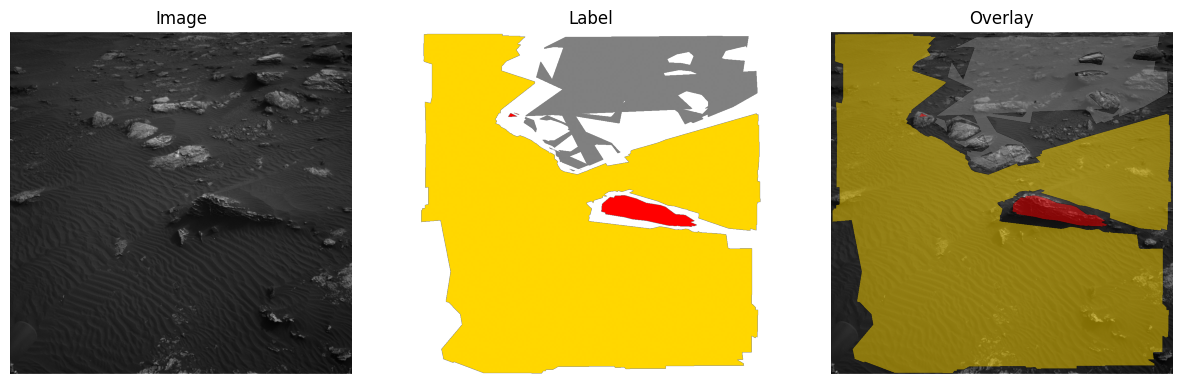

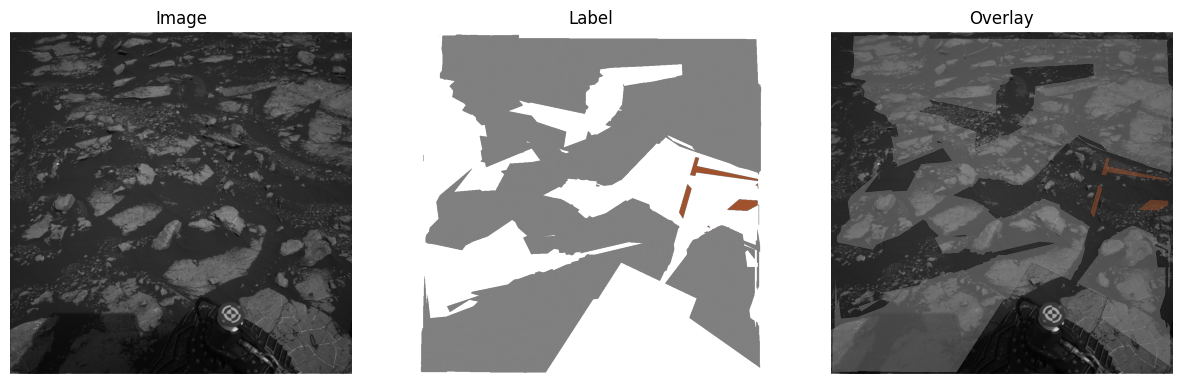

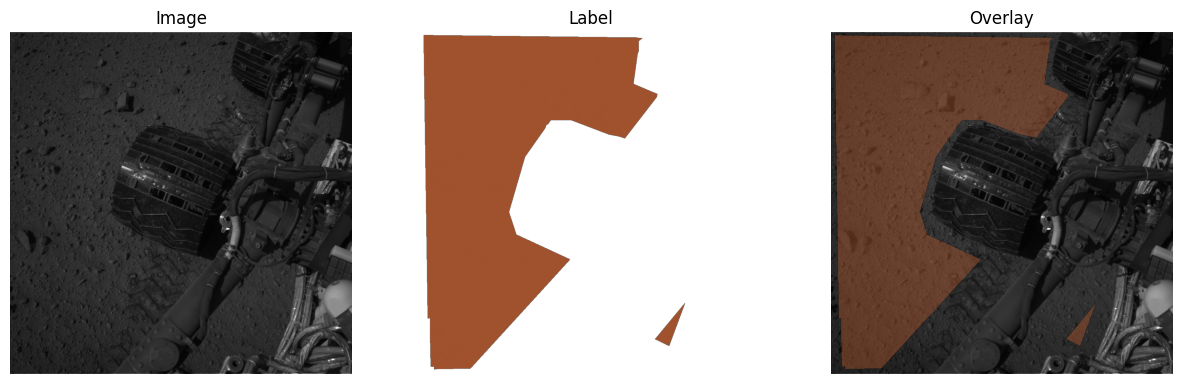

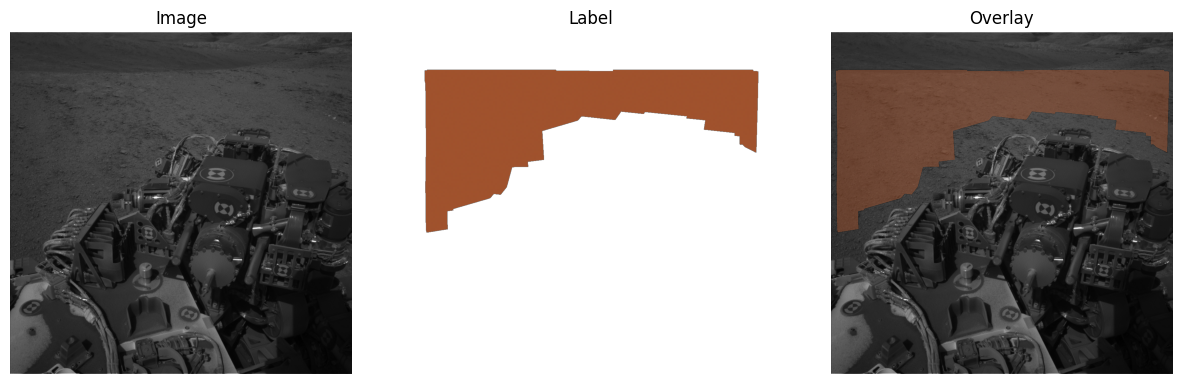

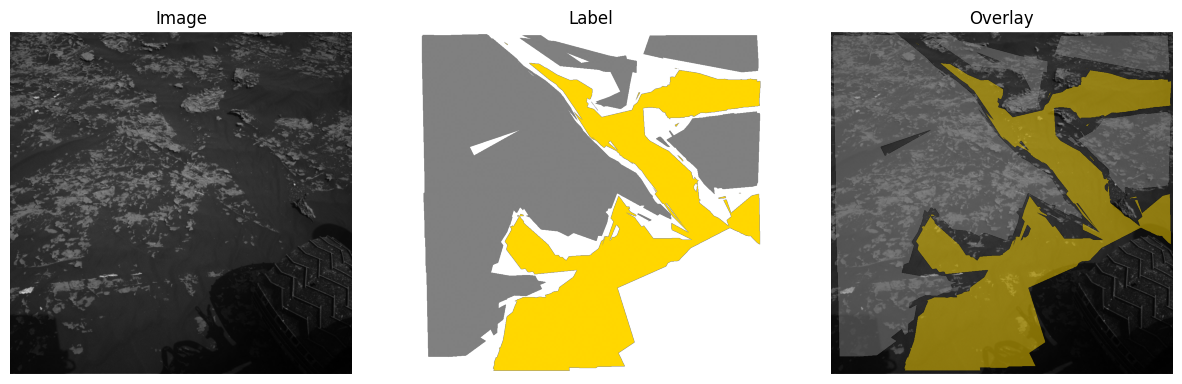

In [11]:
# three panels per example, photo | label | photo with label on top
from matplotlib.colors import ListedColormap

cmap = ListedColormap(["sienna", "gray", "gold", "red"]) # soil, bedrock, sand, big rock

for lbl in sample_train[:5]:
    img_path = IMG_DIR / (lbl.stem + ".JPG")

    with Image.open(img_path) as im:
        img_arr = np.array(im)

    with Image.open(lbl) as lb:
        lbl_arr = np.array(lb)

    masked = np.ma.masked_equal(lbl_arr, 255) # hides unlabelled pixels, the 255s

    fig, axes = plt.subplots(1, 3, figsize=(15, 5)) # a new figure per example 

    axes[0].imshow(img_arr, cmap="gray")
    axes[0].set_title("Image")

    axes[1].imshow(masked, cmap=cmap, vmin=0, vmax=3)
    axes[1].set_title("Label")

    axes[2].imshow(img_arr, cmap="gray") # photo underneath
    axes[2].imshow(masked, cmap=cmap, vmin=0, vmax=3, alpha=0.5) # label on top
    axes[2].set_title("Overlay")

    for ax in axes:
        ax.axis("off") # hid ethe axis ticks
    plt.show()

1. The labels are rough polygons, not precise outlines. Crowdsourced labellers drew shapes with straight edges, so boundaries don’t follow the actual edges of rocks or sand. In example 1, the sand polygon covers parts of rocks. Consequence: even a perfect model can’t score 100%, and predictions near boundaries will look “wrong” against these labels.

2. The rover is correctly left unlabelled. In examples 2, 3, 4 and 5, the wheels and rover body stay grey (no colour), as the documentation said.

3. Far-away areas are unlabelled too. In example 4, the top band near the horizon has no label: that’s the >30 m range mask at work.

4. “Big rock” is under-labelled. This is the most important observation:

    In example 1 we can see many rocks, but only one is labelled big rock.
    In example 2, the rocks are labelled as bedrock.
    So “big rock” isn’t just rare: it’s inconsistently labelled.

5. Big unlabelled gaps. Labellers often skipped areas between regions (the white gaps), matching the 20–80% unlabelled you measured.

6. Brightness varies a lot. Some images are very dark. Later that motivates normalisation and brightness augmentation.

### 5. **Class balance** 

pixel share %: [37.69 51.08 10.48  0.75]
images containing class: [253 325 157  72] of 500


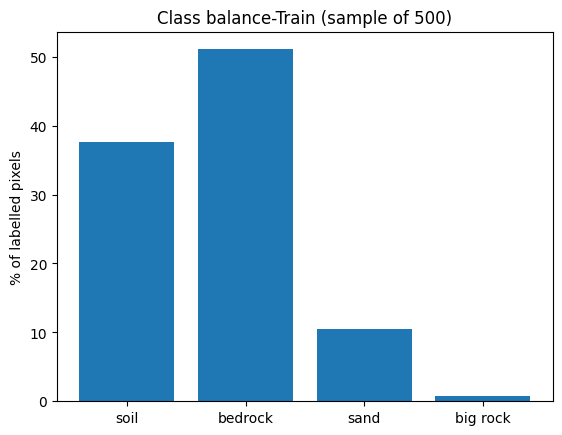

pixel share %: [51.35 22.39 26.19  0.07]
images containing class: [150 142 110   5] of 322


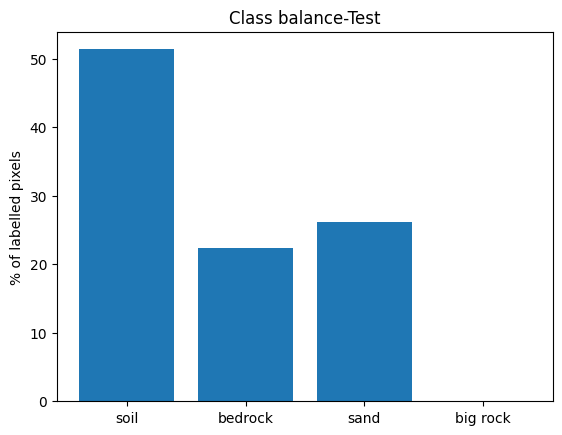

In [12]:
# measuring how rare each class is 

random.seed(0)
sample_500 = random.sample(train_lbls, 500)
totals = np.zeros(4, dtype=np.int64) # an array of four zeros, pixels per class
present = np.zeros(4, dtype=np.int64)  # images containing each class

for p in sample_500: # for each label in a larger sample, count the pixels per class ignoring 255
    with Image.open(p) as lb:
        arr = np.array(lb)
    counts = np.bincount(arr[arr != 255], minlength=4)  
    totals += counts 
    present += counts > 0

percent = totals / totals.sum() * 100
classes = ["soil", "bedrock", "sand", "big rock"]

print("pixel share %:", percent.round(2))
print("images containing class:", present, "of", len(sample_500))

plt.bar(classes, percent)
plt.ylabel("% of labelled pixels")
plt.title("Class balance-Train (sample of 500)")
plt.show()

# now, for the test set 

totals_test = np.zeros(4, dtype=np.int64) # an array of four zeros, pixels per class
present_test = np.zeros(4, dtype=np.int64)  # images containing each class

for p in test_lbls: # for each label in a larger sample, count the pixels per class ignoring 255
    with Image.open(p) as lb:
        arr = np.array(lb)
    counts = np.bincount(arr[arr != 255], minlength=4)  
    totals_test += counts 
    present_test += counts > 0

percent_test = totals_test / totals_test.sum() * 100
classes = ["soil", "bedrock", "sand", "big rock"]

print("pixel share %:", percent_test.round(2))
print("images containing class:", present_test, "of", len(test_lbls))

plt.bar(classes, percent_test)
plt.ylabel("% of labelled pixels")
plt.title("Class balance-Test")
plt.show()

Train (sample of 500):

- Bedrock 51%, soil 38%, sand 10.5%, big rock 0.75%

- Big rock appears in 72 of 500 images (14%), but covers only 0.75% of 
pixels. So it shows up fairly often, but always as tiny areas. 

Test (min3, all 322):

- Soil 51%, sand 26%, bedrock 22%, big rock 0.07%

- Big rock appears in only 5 of 322 images.


1. Strong class imbalance.
Big rock is about 70 times rarer than bedrock. A model that never predicts big rock would lose less than 1% of pixel accuracy, so overall accuracy would look great while one class completely fails.

    → Use per-class IoU and mean IoU, not pixel accuracy, as your main metric. This is also why the paper’s 96% accuracy says little on its own.

    → This gives a natural Phase 6 experiment: weighted cross-entropy / Dice / focal loss vs plain cross-entropy.

2. Big rock can’t be measured reliably on min3.
With 5 images and 0.07% of pixels, any big-rock score on min3 is basically noise.

    → Run the same code on min1 to see if it has more big rock. If it does, report big-rock performance there, and/or report mIoU over the three main classes plus big rock separately, clearly flagged.

3. Train and test have different distributions.
Train is mostly bedrock; test is mostly soil, with 2.5 times more sand. This is a distribution shift: the expert test images come from different terrain than the average training image.

### 6. **Camera types** 
- ncam (Navcam): greyscale stereo images that the rover uses to drive.
- mcam (Mastcam): colour images for science and for human operators, and usually without range data (the distance information behind the “>30 m away” mask).

#### Decisions
1. **Camera:** train on ncam (Navcam) only: the driving camera, has rover/range masks, greyscale.
2. **Later experiment:** test transfer to mcam (Mastcam, colour).
3. **Input:** 1 channel (all images are 1024×1024 greyscale, mode L).
4. **Resolution:** resize images and labels to 512×512 for training (faster, less memory). Labels use nearest-neighbour interpolation so no fake class values appear.
5. **Classes:** 4 classes: 0 soil, 1 bedrock, 2 sand, 3 big rock.
6. **Unlabelled pixels:** value 255 is ignored in the loss (`ignore_index=255`) and in all metrics.
7. **Empty labels:** skip labels that contain only 255 (about 2% of train, about 10% of test in a sample of 50).
8. **Unlabelled images:** the 1,741 images without any label are not used.
9. **Splits:** train = `labels/train` (16,064); validation = a random part of train (e.g. 10%); test = expert labels, untouched until final evaluation.
10. **Main evaluation:** test set `min3` (322 labels, strictest expert agreement). Optionally also report `min1`/`min2`, since min3 is very sparse and may contain very few big-rock pixels.
11. **Masks:** the rover (MXY) and range (RNG-30M) masks are already applied in the labels; use them to hide predictions in those regions in evaluation and visualisations.
12. **Main metric:** per-class IoU and mean IoU (not pixel accuracy, which is misleading because of class imbalance).
13. **Big rock:** too rare in min3 (0.07%, 5 images) to evaluate reliably → also report on min1 (check its counts); flag big-rock results as low-confidence.
14. **Distribution shift:** train is bedrock-heavy, test is soil/sand-heavy → expect a validation/test gap; discuss in README.
15. **Phase 6 experiment:** imbalance-aware losses (weighted CE, Dice, focal) vs plain CE, judged by big-rock and sand IoU.
